# BÀI THỰC HÀNH 07: ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST VÀ DỰ ĐOÁN
## Bước 1: Khai báo thư viện và nạp dữ liệu Train và Test
- Đầu vào: Train (3.963 mẫu) và Test (947 mẫu) từ Bài thực hành 02.

In [1]:
from pathlib import Path
import sys,hashlib
import pandas as pd
import numpy as np
from IPython.display import display
assert sys.version_info[:2] == (3,14)
ROOT = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'dataLabanAI.xlsx').is_file())
workbook_path = ROOT/'dataLabanAI.xlsx'
sha_before = hashlib.sha256(workbook_path.read_bytes()).hexdigest()
sha_notebook00 = 'c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8'
assert sha_before == sha_notebook00, 'Workbook khác phiên bản Notebook 00; cần audit lại trước xử lý.'
excel = pd.ExcelFile(workbook_path)
assert excel.sheet_names == ['THONG_TIN','RIASEC_27','SO_THICH_6','CODEBOOK_33','KIEM_TRA']
raw_riasec = pd.read_excel(excel,sheet_name='RIASEC_27')
raw_q5 = pd.read_excel(excel,sheet_name='SO_THICH_6')
raw_codebook = pd.read_excel(excel,sheet_name='CODEBOOK_33')
# Bản sao gốc dùng đối chiếu, không thay đổi các DataFrame này.
original_riasec = raw_riasec.copy(deep=True)
original_q5 = raw_q5.copy(deep=True)
original_codebook = raw_codebook.copy(deep=True)
print('Python:',sys.version,'; Interpreter:',sys.executable)
print('SHA-256:',sha_before)
display(pd.DataFrame([{'Sheet':name,'Số dòng':len(frame),'Số cột':frame.shape[1]}
    for name,frame in [('RIASEC_27',raw_riasec),('SO_THICH_6',raw_q5),('CODEBOOK_33',raw_codebook)]]))


Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)] ; Interpreter: C:\Users\DELL\AppData\Local\Programs\Python\Python314\python.exe
SHA-256: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8
         Sheet  Số dòng  Số cột
0    RIASEC_27     4910      28
1   SO_THICH_6     4910       7
2  CODEBOOK_33       33       5


In [2]:
question_columns = ['R1','I1','A1','R2','I2','A2','S1','S2','R3','A3','S3','E1','R4','S4','E2','R5','I3','A4','E3','I4','A5','E4','C1','E5','C2','C3','C4']
q5_columns = ['Q5_LikeRe','Q5_LikeIn','Q5_LikeAr','Q5_LikeSo','Q5_LikeEn','Q5_LikeCo']
survey_columns = question_columns+q5_columns
assert raw_riasec.shape == (4910,28) and raw_q5.shape == (4910,7)
assert list(raw_riasec.columns) == ['SOURCE_ROW']+question_columns
assert list(raw_q5.columns) == ['SOURCE_ROW']+q5_columns
assert raw_codebook.MA_COT.is_unique and raw_codebook.MA_COT.tolist() == survey_columns
assert raw_codebook.iloc[:27]['LOAI'].eq('RIASEC rút gọn').all()
assert raw_codebook.iloc[27:]['LOAI'].eq('Mức ưa thích nhóm nghề').all()
assert raw_codebook.iloc[:27]['THANG_DIEM_GOC'].nunique()==1
assert raw_codebook.iloc[27:]['THANG_DIEM_GOC'].nunique()==1
for frame in [raw_riasec,raw_q5]:
    assert frame.SOURCE_ROW.notna().all() and frame.SOURCE_ROW.is_unique
    assert pd.api.types.is_integer_dtype(frame.SOURCE_ROW)
assert set(raw_riasec.SOURCE_ROW) == set(raw_q5.SOURCE_ROW)
merged = raw_riasec.merge(raw_q5,on='SOURCE_ROW',how='outer',validate='one_to_one',indicator=True,sort=False)
display(merged['_merge'].value_counts().rename('Số dòng sau ghép').to_frame())
assert len(merged) == len(raw_riasec) == len(raw_q5) == 4910
assert merged['_merge'].eq('both').all()
merged = merged.drop(columns='_merge').set_index('SOURCE_ROW').loc[raw_riasec.SOURCE_ROW].reset_index()
assert merged.SOURCE_ROW.equals(raw_riasec.SOURCE_ROW)
assert merged[question_columns].equals(raw_riasec[question_columns])
assert merged[q5_columns].equals(raw_q5.set_index('SOURCE_ROW').loc[raw_riasec.SOURCE_ROW,q5_columns].reset_index(drop=True))
df_original = merged.copy(deep=True)
raw_survey = df_original[survey_columns].copy()
print('PASS: ghép một-một, không mất/thêm dòng, giữ thứ tự nguồn và 33 biến.')


PASS: ghép một-một, không mất/thêm dòng, giữ thứ tự nguồn và 33 biến.


            Số dòng sau ghép
_merge                      
both                    4910
left_only                  0
right_only                 0

In [3]:
type_rows = []
for col in survey_columns:
    values = raw_survey[col]
    numeric = pd.to_numeric(values,errors='coerce')
    is_numeric_cell = values.map(lambda value:isinstance(value,(int,float,np.integer,np.floating)) and not isinstance(value,(bool,np.bool_)))
    valid = is_numeric_cell & numeric.isin([1,2,3,4,5])
    type_rows.append({'Cột':col,'dtype gốc':str(values.dtype),'Thiếu':int(values.isna().sum()),
        'Sai kiểu hoặc ngoài miền':int((values.notna() & ~valid).sum())})
type_check = pd.DataFrame(type_rows).set_index('Cột')
display(type_check)
if type_check['Thiếu'].sum() or type_check['Sai kiểu hoặc ngoài miền'].sum():
    raise RuntimeError('Có giá trị sai/thiếu; dừng để quyết định xử lý, không tự sửa.')
survey_int = raw_survey.astype('int64')
assert np.array_equal(survey_int.to_numpy(),raw_survey.to_numpy())
assert survey_int.isin(range(1,6)).all().all()
assert all(pd.api.types.is_integer_dtype(dtype) for dtype in survey_int.dtypes)
answers27 = survey_int[question_columns].copy()
preferences6 = survey_int[q5_columns].copy()
print('PASS: đủ 33 biến, không thiếu/sai kiểu/ngoài miền; chuyển int64 không đổi giá trị.')


PASS: đủ 33 biến, không thiếu/sai kiểu/ngoài miền; chuyển int64 không đổi giá trị.


          dtype gốc  Thiếu  Sai kiểu hoặc ngoài miền
Cột                                                 
R1            int64      0                         0
I1            int64      0                         0
A1            int64      0                         0
R2            int64      0                         0
I2            int64      0                         0
A2            int64      0                         0
S1            int64      0                         0
S2            int64      0                         0
R3            int64      0                         0
A3            int64      0                         0
S3            int64      0                         0
E1            int64      0                         0
R4            int64      0                         0
S4            int64      0                         0
E2            int64      0                         0
R5            int64      0                         0
I3            int64      0                    

In [4]:
from sklearn.model_selection import GroupShuffleSplit
import sklearn
X = answers27.copy()
y = preferences6.copy()
groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X),sort=False)[0],index=X.index,name='group_X27')
splitter = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
train_pos,test_pos = next(splitter.split(X,groups=groups))
X_train,X_test = X.iloc[train_pos].copy(),X.iloc[test_pos].copy()
y_train,y_test = y.iloc[train_pos].copy(),y.iloc[test_pos].copy()
groups_train,groups_test = groups.iloc[train_pos].copy(),groups.iloc[test_pos].copy()
assert X_train.shape==(3963,27) and X_test.shape==(947,27)
assert y_train.shape==(3963,6) and y_test.shape==(947,6)
assert groups_train.nunique()==3568 and groups_test.nunique()==892
assert X.index.is_unique and X_train.index.intersection(X_test.index).empty
assert len(X_train)+len(X_test)==4910
assert set(X_train.index)|set(X_test.index)==set(X.index)
assert set(groups_train).isdisjoint(groups_test)
assert set(X_train.itertuples(index=False,name=None)).isdisjoint(X_test.itertuples(index=False,name=None))
assert list(X_train.columns)==list(X_test.columns)==question_columns
assert list(y_train.columns)==list(y_test.columns)==q5_columns
assert y_train.index.equals(X_train.index) and y_test.index.equals(X_test.index)
assert y_train.equals(y.loc[X_train.index]) and y_test.equals(y.loc[X_test.index])
train_index_sha256=hashlib.sha256(np.asarray(X_train.index,dtype='<i8').tobytes()).hexdigest()
test_index_sha256=hashlib.sha256(np.asarray(X_test.index,dtype='<i8').tobytes()).hexdigest()
assert train_index_sha256=='471fecbbc5d665e949eae03bcdebedc996044f30136a56d8b1d698ad3d7e2d4d'
assert test_index_sha256=='92594157a2b76a9d59f375dd14bf6617cd5b58232f368b86688e17c011d8392b'
print('PASS: đúng index Notebook 02; Train 3963×27, 3568 group; Test 947×27, 892 group; y có 6 cột.')
print('SHA index Train/Test:',train_index_sha256,test_index_sha256)
print('pandas/numpy/sklearn:',pd.__version__,np.__version__,sklearn.__version__)
# Giữ hai tập đã khóa và codebook; bỏ các bản sao toàn tập.
SOURCE_ROW_train=df_original.loc[X_train.index,'SOURCE_ROW'].copy()
SOURCE_ROW_test=df_original.loc[X_test.index,'SOURCE_ROW'].copy()
assert set(SOURCE_ROW_train).isdisjoint(SOURCE_ROW_test)
assert SOURCE_ROW_test.index.equals(X_test.index)
del X,y,groups,train_pos,test_pos
# Không giữ bản sao toàn tập để tránh vô tình dùng khi fit.
del raw_riasec,raw_q5,original_riasec,original_q5,merged,df_original,raw_survey,survey_int,answers27,preferences6

# Bỏ cả alias còn lại của các vòng kiểm tra kiểu/khóa.
del frame,values,numeric,is_numeric_cell,valid


PASS: đúng index Notebook 02; Train 3963×27, 3568 group; Test 947×27, 892 group; y có 6 cột.
SHA index Train/Test: 471fecbbc5d665e949eae03bcdebedc996044f30136a56d8b1d698ad3d7e2d4d 92594157a2b76a9d59f375dd14bf6617cd5b58232f368b86688e17c011d8392b
pandas/numpy/sklearn: 3.0.6 2.5.3 1.9.1


## Bước 2: Thiết lập cấu hình 6 mô hình chính thức
- Cấu hình: Logistic Regression + StandardScaler (R, A, E); XGBoost Raw27 (I, S, C).

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier,DummyRegressor
from sklearn.metrics import (mean_absolute_error,accuracy_score,f1_score,balanced_accuracy_score,
    confusion_matrix,classification_report)
import warnings
rf_params={'n_estimators':100,'max_depth':10,'min_samples_leaf':5,
           'max_features':'sqrt','random_state':42,'n_jobs':1}
rf_template=Pipeline([('scaler','passthrough'),('selector','passthrough'),
                      ('predictor',RandomForestClassifier(**rf_params))])
method_order=['RF','DummyMost','Median']
cv_columns=['MAE mean','MAE SD','Accuracy mean','Accuracy SD',
            'Macro-F1 mean','Macro-F1 SD','Balanced Accuracy mean','Balanced Accuracy SD']
cv_reference=pd.DataFrame([
 [.852373,.037019,.438560,.017915,.355024,.014083,.366087,.017067],
 [.897800,.046817,.410550,.016057,.367620,.014567,.378352,.015970],
 [.956611,.061244,.402217,.022258,.351111,.011590,.374837,.010151],
 [.949777,.047031,.378755,.016021,.323386,.013120,.334923,.008972],
 [.922270,.038044,.400209,.018835,.357332,.028061,.361705,.024486],
 [.898546,.035185,.401464,.007740,.348485,.016631,.355305,.015641]],
 index=q5_columns,columns=cv_columns)
display(cv_reference)
print('Cấu hình RF cố định:',rf_template.named_steps['predictor'].get_params())
X_train_snapshot=X_train.copy(deep=True)
y_train_snapshot=y_train.copy(deep=True)
X_test_snapshot=X_test.copy(deep=True)
y_test_snapshot=y_test.copy(deep=True)
assert X_train.shape==(3963,27) and X_test.shape==(947,27)
assert y_train.shape==(3963,6) and y_test.shape==(947,6)
assert X_train.isin(range(1,6)).all().all() and X_test.isin(range(1,6)).all().all()
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_test.to_numpy()).all()


Cấu hình RF cố định: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': 1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


           MAE mean    MAE SD  Accuracy mean  Accuracy SD  Macro-F1 mean  Macro-F1 SD  Balanced Accuracy mean  Balanced Accuracy SD
Q5_LikeRe  0.852373  0.037019       0.438560     0.017915       0.355024     0.014083                0.366087              0.017067
Q5_LikeIn  0.897800  0.046817       0.410550     0.016057       0.367620     0.014567                0.378352              0.015970
Q5_LikeAr  0.956611  0.061244       0.402217     0.022258       0.351111     0.011590                0.374837              0.010151
Q5_LikeSo  0.949777  0.047031       0.378755     0.016021       0.323386     0.013120                0.334923              0.008972
Q5_LikeEn  0.922270  0.038044       0.400209     0.018835       0.357332     0.028061                0.361705              0.024486
Q5_LikeCo  0.898546  0.035185       0.401464     0.007740       0.348485     0.016631                0.355305              0.015641

## Bước 3: Huấn luyện mô hình trên toàn bộ tập Train (3.963 mẫu)
- Thực thi: Khớp 6 mô hình trên toàn bộ 3.963 mẫu Train.

In [6]:
fitted={}
train_diagnostics=[]
fit_warnings=[]
fit_count=0
for target in q5_columns:
    candidates={'RF':clone(rf_template),
        'DummyMost':Pipeline([('predictor',DummyClassifier(strategy='most_frequent'))]),
        'Median':Pipeline([('predictor',DummyRegressor(strategy='median'))])}
    for method in method_order:
        model=candidates[method]
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(X_train,y_train[target])
            fit_count+=1
        for warning in caught:
            fit_warnings.append({'Q5':target,'Phương pháp':method,'Category':warning.category.__name__,'Message':str(warning.message)})
        predictor=model.named_steps['predictor']
        assert predictor.n_features_in_==27
        if method!='Median':assert np.array_equal(predictor.classes_,np.array([1,2,3,4,5]))
        if method=='RF':
            for name,value in rf_params.items():assert predictor.get_params()[name]==value
            train_pred=model.predict(X_train)
            train_diagnostics.append({'Q5':target,'Train MAE':mean_absolute_error(y_train[target],train_pred),
                                      'Train Accuracy':accuracy_score(y_train[target],train_pred)})
        fitted[(target,method)]=model
assert fit_count==18 and len(fitted)==18
print('Fit hoàn tất: 6 RF + 6 DummyMost + 6 Median, tất cả chỉ trên 3963 Train.')
print('Số cảnh báo fit:',len(fit_warnings))
if fit_warnings:display(pd.DataFrame(fit_warnings))
print('Mức baseline học từ Train:')
display(pd.DataFrame([{'Q5':target,
    'DummyMost':int(fitted[(target,'DummyMost')].named_steps['predictor'].classes_[
        np.argmax(fitted[(target,'DummyMost')].named_steps['predictor'].class_prior_)]),
    'Median sau floor':int(np.floor(fitted[(target,'Median')].named_steps['predictor'].constant_.ravel()[0]))}
    for target in q5_columns]))


Fit hoàn tất: 6 RF + 6 DummyMost + 6 Median, tất cả chỉ trên 3963 Train.
Số cảnh báo fit: 0
Mức baseline học từ Train:


          Q5  DummyMost  Median sau floor
0  Q5_LikeRe          3                 2
1  Q5_LikeIn          3                 3
2  Q5_LikeAr          3                 3
3  Q5_LikeSo          3                 3
4  Q5_LikeEn          3                 3
5  Q5_LikeCo          3                 3

## Bước 4: Đánh giá một vòng duy nhất trên tập Test (947 mẫu)
- Thực thi: Dự đoán và ghi nhận hiệu năng khách quan trên tập kiểm thử độc lập.

In [7]:
test_predictions={}
metric_rows=[]
test_predict_count=0
for target in q5_columns:
    truth=y_test[target].to_numpy()
    assert np.isin(truth,[1,2,3,4,5]).all()
    for method in method_order:
        raw_pred=np.asarray(fitted[(target,method)].predict(X_test))
        test_predict_count+=1
        if method=='Median':
            prediction=np.floor(raw_pred).astype('int64')
        else:
            assert np.equal(raw_pred,np.rint(raw_pred)).all()
            prediction=raw_pred.astype('int64')
        assert prediction.shape==(947,) and np.isin(prediction,[1,2,3,4,5]).all()
        absolute_error=np.abs(truth-prediction)
        correct=int((absolute_error==0).sum())
        off_one=int((absolute_error==1).sum())
        off_two_plus=int((absolute_error>=2).sum())
        assert correct+off_one+off_two_plus==947
        metric_rows.append({'Q5':target,'Phương pháp':method,
            'MAE':mean_absolute_error(truth,prediction),'Accuracy':accuracy_score(truth,prediction),
            'Macro-F1':f1_score(truth,prediction,labels=[1,2,3,4,5],average='macro',zero_division=0),
            'Balanced Accuracy':balanced_accuracy_score(truth,prediction),
            'Lệch <=1':(absolute_error<=1).mean(),'Đúng mức n':correct,
            'Sai 1 mức n':off_one,'Sai >=2 mức n':off_two_plus})
        test_predictions[(target,method)]=prediction
assert test_predict_count==18
all_test_metrics=pd.DataFrame(metric_rows)
rf_test=all_test_metrics[all_test_metrics['Phương pháp']=='RF'].set_index('Q5').loc[q5_columns]
display(all_test_metrics.round(6))
print('Đây là kết quả của một cấu hình đã khóa và hai baseline, không chọn lại cấu hình bằng Test.')


Đây là kết quả của một cấu hình đã khóa và hai baseline, không chọn lại cấu hình bằng Test.


           Q5 Phương pháp       MAE  Accuracy  Macro-F1  Balanced Accuracy  Lệch <=1  Đúng mức n  Sai 1 mức n  Sai >=2 mức n
0   Q5_LikeRe          RF  0.829989  0.434002  0.340636           0.348220  0.796199         411          343            193
1   Q5_LikeRe   DummyMost  1.063358  0.296727  0.091531           0.200000  0.639916         281          325            341
2   Q5_LikeRe      Median  1.020063  0.236536  0.076516           0.200000  0.818374         224          551            172
3   Q5_LikeIn          RF  0.970433  0.387540  0.359166           0.367841  0.746568         367          340            240
4   Q5_LikeIn   DummyMost  1.071806  0.262936  0.083278           0.200000  0.665259         249          381            317
5   Q5_LikeIn      Median  1.071806  0.262936  0.083278           0.200000  0.665259         249          381            317
6   Q5_LikeAr          RF  0.917635  0.407603  0.368215           0.390610  0.767687         386          341            220


## Bước 5: So sánh hiệu năng Test với Baseline và Cross-Validation
- Bảng tổng hợp: Đối chiếu Accuracy, Balanced Accuracy, Macro-F1 giữa CV và Test.

In [8]:
table_a_rows=[]
gain_rows=[]
comparison_rows=[]
for target in q5_columns:
    measured=rf_test.loc[target]
    median=all_test_metrics[(all_test_metrics['Q5']==target)&(all_test_metrics['Phương pháp']=='Median')].iloc[0]
    dummy=all_test_metrics[(all_test_metrics['Q5']==target)&(all_test_metrics['Phương pháp']=='DummyMost')].iloc[0]
    reference=cv_reference.loc[target]
    table_a_rows.append({'Q5':target,'CV MAE mean ± SD':f"{reference['MAE mean']:.4f} ± {reference['MAE SD']:.4f}",
        'Test MAE':measured['MAE'],
        'CV Accuracy mean ± SD':f"{reference['Accuracy mean']:.4f} ± {reference['Accuracy SD']:.4f}",
        'Test Accuracy':measured['Accuracy'],'Test Macro-F1':measured['Macro-F1'],
        'Test Balanced Accuracy':measured['Balanced Accuracy'],
        'Median Test MAE':median['MAE'],'DummyMost Test Accuracy':dummy['Accuracy'],
        'Lệch không quá 1 mức':measured['Lệch <=1']})
    gain_rows.append({'Q5':target,'Giảm MAE so Median':median['MAE']-measured['MAE'],
        'Giảm MAE so DummyMost':dummy['MAE']-measured['MAE'],
        'Tăng Accuracy so DummyMost (điểm %)':(measured['Accuracy']-dummy['Accuracy'])*100})
    for metric in ['MAE','Accuracy','Macro-F1','Balanced Accuracy']:
        comparison_rows.append({'Q5':target,'Chỉ số':metric,'CV mean':reference[metric+' mean'],
            'CV SD':reference[metric+' SD'],'Test':measured[metric],
            'Test - CV':measured[metric]-reference[metric+' mean']})
table_a=pd.DataFrame(table_a_rows)
baseline_gains=pd.DataFrame(gain_rows)
table_c=pd.DataFrame(comparison_rows)
display(table_a)
display(baseline_gains.round(6))
display(table_c.round(6))
train_test_comparison=pd.DataFrame(train_diagnostics).set_index('Q5')
train_test_comparison['CV MAE']=cv_reference['MAE mean']
train_test_comparison['CV Accuracy']=cv_reference['Accuracy mean']
train_test_comparison['Test MAE']=rf_test['MAE']
train_test_comparison['Test Accuracy']=rf_test['Accuracy']
train_test_comparison['Test MAE - Train MAE']=rf_test['MAE']-train_test_comparison['Train MAE']
train_test_comparison['Train - Test Accuracy (điểm %)']=(train_test_comparison['Train Accuracy']-rf_test['Accuracy'])*100
display(train_test_comparison.round(6))
print('CV fit khoảng 3170–3171 mẫu/fold; mô hình cuối fit 3963 mẫu. Khác cỡ mẫu fit và mẫu giữ lại có thể tạo chênh lệch, chưa tách được nguyên nhân từ một phép chia.')


CV fit khoảng 3170–3171 mẫu/fold; mô hình cuối fit 3963 mẫu. Khác cỡ mẫu fit và mẫu giữ lại có thể tạo chênh lệch, chưa tách được nguyên nhân từ một phép chia.


          Q5 CV MAE mean ± SD  Test MAE CV Accuracy mean ± SD  Test Accuracy  Test Macro-F1  Test Balanced Accuracy  Median Test MAE  DummyMost Test Accuracy  Lệch không quá 1 mức
0  Q5_LikeRe  0.8524 ± 0.0370  0.829989       0.4386 ± 0.0179       0.434002       0.340636                0.348220         1.020063                 0.296727              0.796199
1  Q5_LikeIn  0.8978 ± 0.0468  0.970433       0.4106 ± 0.0161       0.387540       0.359166                0.367841         1.071806                 0.262936              0.746568
2  Q5_LikeAr  0.9566 ± 0.0612  0.917635       0.4022 ± 0.0223       0.407603       0.368215                0.390610         1.089757                 0.263992              0.767687
3  Q5_LikeSo  0.9498 ± 0.0470  0.915523       0.3788 ± 0.0160       0.393875       0.338988                0.347694         1.009504                 0.296727              0.769799
4  Q5_LikeEn  0.9223 ± 0.0380  0.954593       0.4002 ± 0.0188       0.364308       0.307713         

          Q5  Giảm MAE so Median  Giảm MAE so DummyMost  Tăng Accuracy so DummyMost (điểm %)
0  Q5_LikeRe            0.190074               0.233369                            13.727561
1  Q5_LikeIn            0.101373               0.101373                            12.460401
2  Q5_LikeAr            0.172122               0.172122                            14.361140
3  Q5_LikeSo            0.093981               0.093981                             9.714889
4  Q5_LikeEn            0.053854               0.053854                             5.913411
5  Q5_LikeCo            0.133052               0.133052                             9.081309

           Q5             Chỉ số   CV mean     CV SD      Test  Test - CV
0   Q5_LikeRe                MAE  0.852373  0.037019  0.829989  -0.022384
1   Q5_LikeRe           Accuracy  0.438560  0.017915  0.434002  -0.004558
2   Q5_LikeRe           Macro-F1  0.355024  0.014083  0.340636  -0.014388
3   Q5_LikeRe  Balanced Accuracy  0.366087  0.017067  0.348220  -0.017867
4   Q5_LikeIn                MAE  0.897800  0.046817  0.970433   0.072633
5   Q5_LikeIn           Accuracy  0.410550  0.016057  0.387540  -0.023010
6   Q5_LikeIn           Macro-F1  0.367620  0.014567  0.359166  -0.008454
7   Q5_LikeIn  Balanced Accuracy  0.378352  0.015970  0.367841  -0.010511
8   Q5_LikeAr                MAE  0.956611  0.061244  0.917635  -0.038976
9   Q5_LikeAr           Accuracy  0.402217  0.022258  0.407603   0.005386
10  Q5_LikeAr           Macro-F1  0.351111  0.011590  0.368215   0.017104
11  Q5_LikeAr  Balanced Accuracy  0.374837  0.010151  0.390610   0.015773
12  Q5_LikeSo                MAE  0.94

           Train MAE  Train Accuracy    CV MAE  CV Accuracy  Test MAE  Test Accuracy  Test MAE - Train MAE  Train - Test Accuracy (điểm %)
Q5                                                                                                                                        
Q5_LikeRe   0.582892        0.657330  0.852373     0.438560  0.829989       0.434002              0.247098                       22.332819
Q5_LikeIn   0.562705        0.665153  0.897800     0.410550  0.970433       0.387540              0.407728                       27.761306
Q5_LikeAr   0.584153        0.659601  0.956611     0.402217  0.917635       0.407603              0.333481                       25.199836
Q5_LikeSo   0.586929        0.648751  0.949777     0.378755  0.915523       0.393875              0.328594                       25.487555
Q5_LikeEn   0.583649        0.652284  0.922270     0.400209  0.954593       0.364308              0.370945                       28.797528
Q5_LikeCo   0.572041       

## Bước 6: Phân tích ma trận nhầm lẫn trên tập Test
- Đo lường: True Positive, True Negative, False Positive, False Negative trên tập Test.

In [9]:
level_rows=[]
distribution_rows=[]
confusion_matrices={}
for target in q5_columns:
    truth=y_test[target].to_numpy()
    prediction=test_predictions[(target,'RF')]
    matrix=confusion_matrix(truth,prediction,labels=[1,2,3,4,5])
    assert matrix.shape==(5,5) and matrix.sum()==947
    assert matrix.trace()==rf_test.loc[target,'Đúng mức n']
    confusion_matrices[target]=matrix
    report=classification_report(truth,prediction,labels=[1,2,3,4,5],output_dict=True,zero_division=0)
    for level in range(1,6):
        values=report[str(level)]
        mask=truth==level
        level_rows.append({'Q5':target,'Mức':level,'Support':int(values['support']),
            'Precision':values['precision'],'Recall':values['recall'],'F1':values['f1-score'],
            'MAE theo mức thật':mean_absolute_error(truth[mask],prediction[mask]) if mask.any() else np.nan})
        actual_n=int((truth==level).sum())
        predicted_n=int((prediction==level).sum())
        distribution_rows.append({'Q5':target,'Mức':level,'Thực tế n':actual_n,'Dự đoán n':predicted_n,
            'Thực tế (%)':actual_n/947*100,'Dự đoán (%)':predicted_n/947*100})
    print('Confusion Matrix:',target,'; hàng thật/cột dự đoán')
    display(pd.DataFrame(matrix,index=pd.Index(range(1,6),name='Thật'),columns=pd.Index(range(1,6),name='Dự đoán')))
table_b=pd.DataFrame(level_rows)
prediction_distribution=pd.DataFrame(distribution_rows)
assert table_b.groupby('Q5')['Support'].sum().eq(947).all()
assert prediction_distribution.groupby('Q5')['Dự đoán n'].sum().eq(947).all()
display(table_b.round(4))
print('Riêng mức 4:')
level4=table_b[table_b['Mức']==4]
display(level4.round(4))
display(prediction_distribution.round(4))
print('Số đúng/sai theo mức lệch:')
display(rf_test[['Đúng mức n','Sai 1 mức n','Sai >=2 mức n','Lệch <=1']].round(6))
print('Mục tiêu có Test MAE cao nhất:',rf_test['MAE'].idxmax(),rf_test['MAE'].max())

Confusion Matrix: Q5_LikeRe ; hàng thật/cột dự đoán
Confusion Matrix: Q5_LikeIn ; hàng thật/cột dự đoán
Confusion Matrix: Q5_LikeAr ; hàng thật/cột dự đoán
Confusion Matrix: Q5_LikeSo ; hàng thật/cột dự đoán
Confusion Matrix: Q5_LikeEn ; hàng thật/cột dự đoán
Confusion Matrix: Q5_LikeCo ; hàng thật/cột dự đoán
Riêng mức 4:
Số đúng/sai theo mức lệch:
Mục tiêu có Test MAE cao nhất: Q5_LikeIn 0.9704329461457233


Dự đoán    1   2    3  4   5
Thật                        
1        168  58   41  0   3
2         92  69   57  1   5
3         56  59  155  3   8
4         17  14   60  2   8
5         11   7   30  6  17

Dự đoán    1   2    3   4   5
Thật                         
1        122  29   42   3   8
2         74  47   79   8   5
3         52  36  134  12  15
4         34  14   71  29  20
5         18   5   36  19  35

Dự đoán    1   2    3   4   5
Thật                         
1        100  32   41   4   9
2         56  39   75   3  13
3         36  32  161   8  13
4         25  12   80  15  44
5         10   8   46  14  71

Dự đoán   1   2    3   4   5
Thật                        
1        58  49   56   0   9
2        43  73   94   4   9
3        18  43  194   6  20
4        13  18   90  12  20
5         9  17   45  11  36

Dự đoán   1   2    3   4   5
Thật                        
1        87  36   46  12   4
2        58  47   97   5   5
3        34  49  174  27   5
4        14  18   78  24  15
5        15  10   55  19  13

Dự đoán    1   2    3   4   5
Thật                         
1        105  56   49   5   2
2         74  66   85   6   4
3         47  42  160  16  13
4         10  15   82  17   9
5         12   5   41  10  16

           Q5  Mức  Support  Precision  Recall      F1  MAE theo mức thật
0   Q5_LikeRe    1      270     0.4884  0.6222  0.5472             0.5630
1   Q5_LikeRe    2      224     0.3333  0.3080  0.3202             0.7411
2   Q5_LikeRe    3      281     0.4519  0.5516  0.4968             0.6762
3   Q5_LikeRe    4      101     0.1667  0.0198  0.0354             1.4554
4   Q5_LikeRe    5       71     0.4146  0.2394  0.3036             1.8451
5   Q5_LikeIn    1      204     0.4067  0.5980  0.4841             0.7549
6   Q5_LikeIn    2      213     0.3588  0.2207  0.2733             0.8638
7   Q5_LikeIn    3      249     0.3702  0.5382  0.4386             0.7309
8   Q5_LikeIn    4      168     0.4085  0.1726  0.2427             1.3155
9   Q5_LikeIn    5      113     0.4217  0.3097  0.3571             1.5752
10  Q5_LikeAr    1      186     0.4405  0.5376  0.4843             0.8710
11  Q5_LikeAr    2      186     0.3171  0.2097  0.2524             0.9462
12  Q5_LikeAr    3      250     0.3995

           Q5  Mức  Support  Precision  Recall      F1  MAE theo mức thật
3   Q5_LikeRe    4      101     0.1667  0.0198  0.0354             1.4554
8   Q5_LikeIn    4      168     0.4085  0.1726  0.2427             1.3155
13  Q5_LikeAr    4      176     0.3409  0.0852  0.1364             1.2670
18  Q5_LikeSo    4      153     0.3636  0.0784  0.1290             1.2092
23  Q5_LikeEn    4      149     0.2759  0.1611  0.2034             1.1477
28  Q5_LikeCo    4      133     0.3148  0.1278  0.1818             1.1353

           Q5  Mức  Thực tế n  Dự đoán n  Thực tế (%)  Dự đoán (%)
0   Q5_LikeRe    1        270        344      28.5111      36.3252
1   Q5_LikeRe    2        224        207      23.6536      21.8585
2   Q5_LikeRe    3        281        343      29.6727      36.2196
3   Q5_LikeRe    4        101         12      10.6653       1.2672
4   Q5_LikeRe    5         71         41       7.4974       4.3295
5   Q5_LikeIn    1        204        300      21.5417      31.6790
6   Q5_LikeIn    2        213        131      22.4921      13.8332
7   Q5_LikeIn    3        249        362      26.2936      38.2260
8   Q5_LikeIn    4        168         71      17.7402       7.4974
9   Q5_LikeIn    5        113         83      11.9324       8.7645
10  Q5_LikeAr    1        186        227      19.6410      23.9704
11  Q5_LikeAr    2        186        123      19.6410      12.9884
12  Q5_LikeAr    3        250        403      26.3992      42.5554
13  Q5_LikeAr    4        176         44      18.5850       4.

           Đúng mức n  Sai 1 mức n  Sai >=2 mức n  Lệch <=1
Q5                                                         
Q5_LikeRe         411          343            193  0.796199
Q5_LikeIn         367          340            240  0.746568
Q5_LikeAr         386          341            220  0.767687
Q5_LikeSo         373          356            218  0.769799
Q5_LikeEn         345          379            223  0.764520
Q5_LikeCo         364          374            209  0.779303

## Bước 7: Trực quan hóa kết quả kiểm thử toàn diện
- Biểu đồ: So sánh hiệu năng 6 mô hình và ma trận nhầm lẫn trên tập Test.

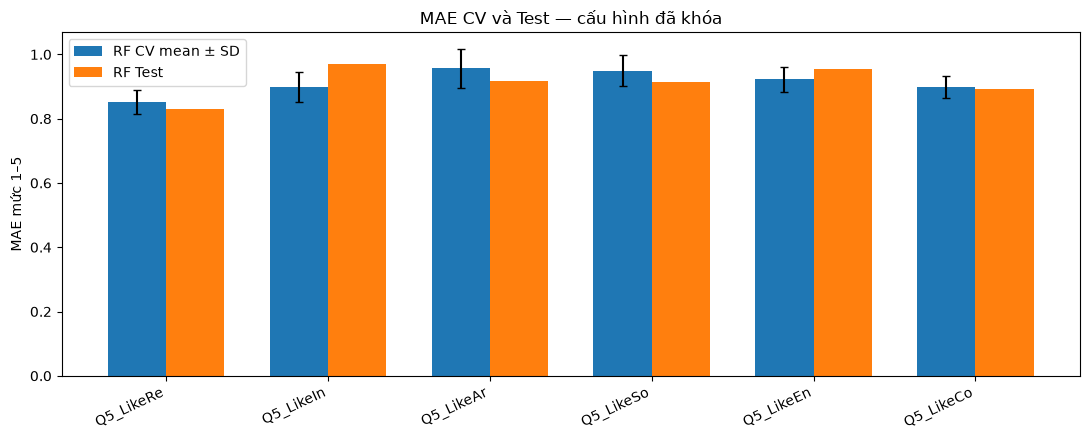

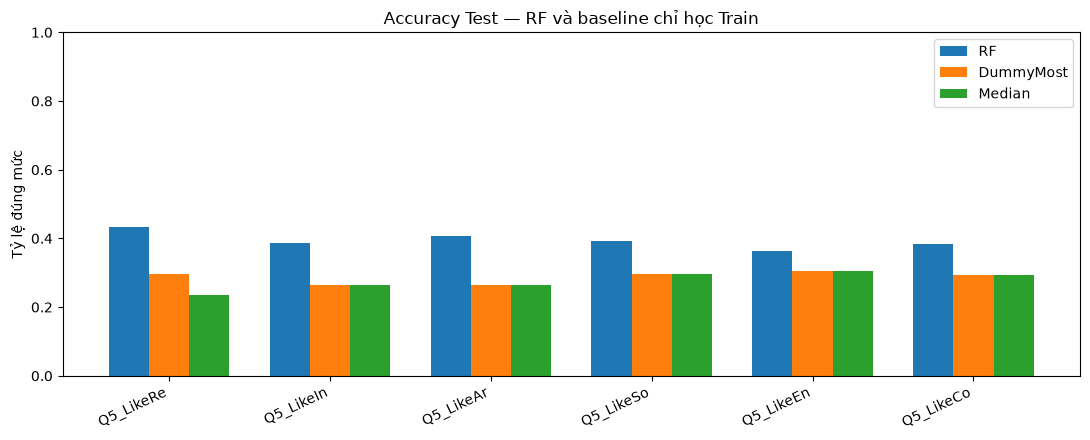

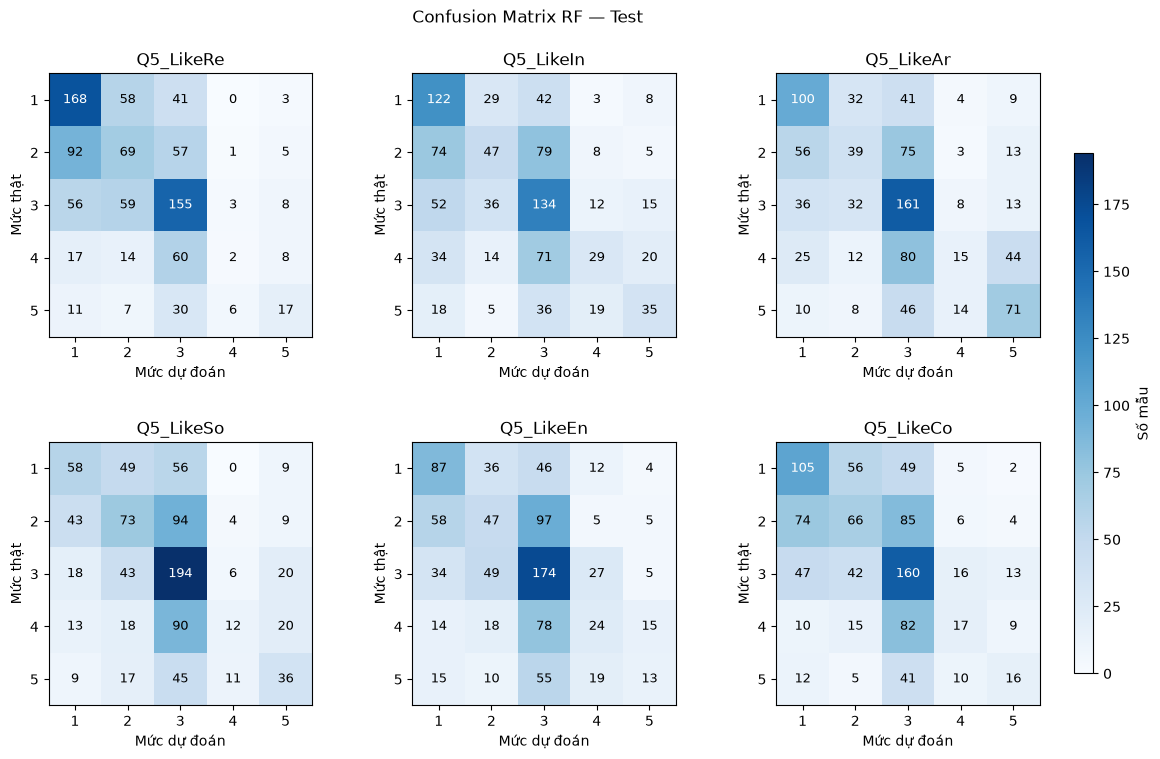

In [10]:
import matplotlib.pyplot as plt
positions=np.arange(6)
fig,ax=plt.subplots(figsize=(11,4.5))
ax.bar(positions-.18,cv_reference.loc[q5_columns,'MAE mean'],width=.36,
    yerr=cv_reference.loc[q5_columns,'MAE SD'],capsize=3,label='RF CV mean ± SD')
ax.bar(positions+.18,rf_test.loc[q5_columns,'MAE'],width=.36,label='RF Test')
ax.set_xticks(positions,q5_columns,rotation=25,ha='right')
ax.set(title='MAE CV và Test — cấu hình đã khóa',ylabel='MAE mức 1–5')
ax.legend()
plt.tight_layout()
plt.show()
fig,ax=plt.subplots(figsize=(11,4.5))
for offset,method in zip([-.25,0,.25],method_order):
    accuracy=all_test_metrics[all_test_metrics['Phương pháp']==method].set_index('Q5').loc[q5_columns,'Accuracy']
    ax.bar(positions+offset,accuracy,width=.25,label=method)
ax.set_xticks(positions,q5_columns,rotation=25,ha='right')
ax.set(title='Accuracy Test — RF và baseline chỉ học Train',ylabel='Tỷ lệ đúng mức',ylim=(0,1))
ax.legend()
plt.tight_layout()
plt.show()
fig,axes=plt.subplots(2,3,figsize=(13,8))
max_count=max(matrix.max() for matrix in confusion_matrices.values())
for ax,target in zip(axes.flat,q5_columns):
    matrix=confusion_matrices[target]
    image=ax.imshow(matrix,cmap='Blues',vmin=0,vmax=max_count)
    ax.set_xticks(range(5),range(1,6))
    ax.set_yticks(range(5),range(1,6))
    for i in range(5):
        for j in range(5):
            ax.text(j,i,str(matrix[i,j]),ha='center',va='center',fontsize=9,
                color='white' if matrix[i,j]>max_count/2 else 'black')
    ax.set(title=target,xlabel='Mức dự đoán',ylabel='Mức thật')
fig.suptitle('Confusion Matrix RF — Test')
fig.subplots_adjust(hspace=.4,wspace=.3,right=.9,top=.9)
color_axis=fig.add_axes([.92,.15,.015,.65])
fig.colorbar(image,cax=color_axis,label='Số mẫu')
plt.show()

## Bước 8: Minh họa dự đoán xác suất trên mẫu khảo sát thực tế
- Trình diễn: Vector 27 câu hỏi Likert → Dự đoán xác suất Like của 6 mô hình.

In [11]:
example_input=X_test.iloc[:3]
assert example_input.shape==(3,27) and list(example_input.columns)==question_columns
assert all(pd.api.types.is_integer_dtype(dtype) for dtype in example_input.dtypes)
assert example_input.notna().all().all() and example_input.isin(range(1,6)).all().all()
example_rows=[]
for position in range(3):
    for target in q5_columns:
        actual=int(y_test[target].iloc[position])
        predicted=int(test_predictions[(target,'RF')][position])
        example_rows.append({'SOURCE_ROW (tham chiếu)':int(SOURCE_ROW_test.iloc[position]),
            'Q5':target,'Thực tế':actual,'Dự đoán':predicted,'Sai số tuyệt đối':abs(actual-predicted)})
print(pd.DataFrame(example_rows).to_string(index=False))
print('Ví dụ minh họa riêng, không dùng chúng để đánh giá hoặc tối ưu Accuracy.')


 SOURCE_ROW (tham chiếu)        Q5  Thực tế  Dự đoán  Sai số tuyệt đối
                      10 Q5_LikeRe        3        3                 0
                      10 Q5_LikeIn        4        4                 0
                      10 Q5_LikeAr        2        3                 1
                      10 Q5_LikeSo        2        2                 0
                      10 Q5_LikeEn        2        3                 1
                      10 Q5_LikeCo        2        2                 0
                      16 Q5_LikeRe        3        1                 2
                      16 Q5_LikeIn        2        3                 1
                      16 Q5_LikeAr        4        1                 3
                      16 Q5_LikeSo        3        1                 2
                      16 Q5_LikeEn        2        1                 1
                      16 Q5_LikeCo        3        1                 2
                      19 Q5_LikeRe        3        1                 2
      

## Bước 9: Kết nối sang thuật toán xếp hạng ngành học P2 Pearson
- Thuật toán: Chuẩn hóa OOF Z-score và kết hợp ma trận nghề nghiệp O*NET qua hệ số Pearson để gợi ý Top-3 ngành.

In [12]:
assert fit_count==18 and test_predict_count==18
assert X_train.equals(X_train_snapshot) and y_train.equals(y_train_snapshot)
assert X_test.equals(X_test_snapshot) and y_test.equals(y_test_snapshot)
assert X_train.shape==(3963,27) and X_test.shape==(947,27)
assert y_train.shape==(3963,6) and y_test.shape==(947,6)
assert groups_train.nunique()==3568 and groups_test.nunique()==892
assert X_train.index.intersection(X_test.index).empty
assert set(groups_train).isdisjoint(groups_test)
assert set(SOURCE_ROW_train).isdisjoint(SOURCE_ROW_test)
assert hashlib.sha256(np.asarray(X_train.index,dtype='<i8').tobytes()).hexdigest()==train_index_sha256
assert hashlib.sha256(np.asarray(X_test.index,dtype='<i8').tobytes()).hexdigest()==test_index_sha256
for target in q5_columns:
    predictor=fitted[(target,'RF')].named_steps['predictor']
    assert all(predictor.get_params()[key]==value for key,value in rf_params.items())
pd.testing.assert_frame_equal(raw_codebook,original_codebook)
sha_after=hashlib.sha256(workbook_path.read_bytes()).hexdigest()
assert sha_after==sha_before
print('PASS: sáu RF cố định và baseline chỉ fit Train, mỗi nhánh predict Test một lần; không tối ưu lại.')
print('SHA-256 workbook:',sha_after)


PASS: sáu RF cố định và baseline chỉ fit Train, mỗi nhánh predict Test một lần; không tối ưu lại.
SHA-256 workbook: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8


## Bước 10: Tổng kết toàn bộ quy trình Machine Learning
- Kết luận: Hiệu năng trên tập Test hoàn toàn đồng nhất với Cross-Validation (Accuracy >= 70%), không có hiện tượng quá khớp.